In [2]:
import numpy as np
import pandas as pd
from mhcgnomes import parse

# 1 Read total data

In [3]:
#DATA_PATH = '/home/denklewer/Data/' #ubuntu
EXPERIMENT_NAME = 'multiple_single_allele_models'
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/'

IEDB_DATA_PATH = DATA_PATH + 'Binding data/IEDB/mhc_ligand_full_single_file/mhc_ligand_full.csv'
NetMHCPan_41_DATA_PATH = DATA_PATH + 'Binding data/NetMHCpan-4.1/NetMHCpan_train/'
NetMHCIIPan_40_DATA_PATH = DATA_PATH + 'Binding data/NetMHCIIpan-4.0/NetMHCIIpan_train/NetMHCIIpan_train/'

In [4]:
netmhc = pd.read_csv(f"{NetMHCIIPan_40_DATA_PATH}/train_BA1.txt", sep="\t", header=None)

In [5]:
netmhc[2]

0        HLA-DPA10103-DPB10201
1        HLA-DPA10103-DPB10201
2        HLA-DPA10103-DPB10201
3        HLA-DPA10103-DPB10201
4        HLA-DPA10103-DPB10201
                 ...          
85362                  H-2-IEd
85363                  H-2-IEd
85364                  H-2-IEk
85365                  H-2-IEk
85366                  H-2-IEk
Name: 2, Length: 85367, dtype: object

In [6]:
netmhc[netmhc[2].str.startswith("H-2")][2].value_counts()

H-2-IAb    1251
H-2-IAd     478
H-2-IEd      96
H-2-IAs      90
H-2-IAk      70
H-2-IEk      49
H-2-IAu      27
H-2-IAq      11
Name: 2, dtype: int64

In [7]:
iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


C:\Users\denkl\AppData\Local\Temp\ipykernel_20156\4180061941.py:1: DtypeWarning: Columns (6,12,13,14,17,18,19,20,21,22,23,24,25,26,27,28,29,30,33,34,35,36,37,38,39,40,41,42,45,46,47,48,49,50,51,52,53,54,55,56,57,60,61,62,63,64,65,66,67,68,70,71,72,73,74,75,76,79,80,81,82,83,84,85,86,87,88,89,92,95,100,101,102,103,104,105,106,109) have mixed types. Specify dtype option on import or set low_memory=False.
  iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


In [8]:
len(iedb_df)

4751412

In [9]:
iedb_df[('Epitope', 'Name')]

0                KLEDLERDL
1                LITGRLQSL
2                 TRVAFAGL
3                 RNTDFFGL
4                EVMPVSMAK
                ...       
4751407          EEVSLPSDP
4751408          EEVSLPSDP
4751409          EEVSLPSDP
4751410    SLQPLALEGSLQKRG
4751411    SLQPLALEGSLQKRG
Name: (Epitope, Name), Length: 4751412, dtype: object

In [10]:
iedb_df[('Epitope', 'Reference Name')]

0                     HDV 26-34
1                          S978
2                    OmpC 73-80
3                  OmpC 132-139
4          SARS Spike (707-715)
                   ...         
4751407               EEVSLPSDP
4751408               EEVSLPSDP
4751409               EEVSLPSDP
4751410                  C20-A1
4751411                  C20-A1
Name: (Epitope, Reference Name), Length: 4751412, dtype: object

In [10]:
iedb_df.columns[30:50]

MultiIndex([('Related Object',                'Name'),
            ('Related Object',   'Starting Position'),
            ('Related Object',     'Ending Position'),
            ('Related Object',                 'IRI'),
            ('Related Object',            'Synonyms'),
            ('Related Object',     'Source Molecule'),
            ('Related Object', 'Source Molecule IRI'),
            ('Related Object',     'Molecule Parent'),
            ('Related Object', 'Molecule Parent IRI'),
            ('Related Object',     'Source Organism'),
            ('Related Object', 'Source Organism IRI'),
            ('Related Object',             'Species'),
            ('Related Object',         'Species IRI'),
            (          'Host',                'Name'),
            (          'Host',                 'IRI'),
            (          'Host',         'Geolocation'),
            (          'Host',     'Geolocation IRI'),
            (          'Host',                 'Sex'),
          

In [11]:
def merge_column_name(column):
    return "_".join(column)

def filter_iedb_dataset(iedb_df, include_qualitative=True, include_mass_spec=True):
    QUALITATIVE_TO_AFFINITY_AND_INEQUALITY = {
    "Negative": (5000.0, ">"),
    "Positive": (500.0, "<"),  # used for mass-spec hits
    "Positive-High": (100.0, "<"),
    "Positive-Intermediate": (1000.0, "<"),
    "Positive-Low": (5000.0, "<"),
    }
    QUALITATIVE_TO_AFFINITY = dict(
        (key, value[0]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    QUALITATIVE_TO_INEQUALITY = dict(
        (key, value[1]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    
    
    
    print("Loaded iedb data: %s" % str(iedb_df.shape))
    filtered_df = iedb_df.copy()
    filtered_df = filtered_df[filtered_df[('Epitope', 'Object Type')] == "Linear peptide"]

    print("Linear peptides only, remaining: %d" % len(filtered_df))
    
    ## Clear bad data
    print("Subselecting to valid peptides (dropping peptides with PTMs). Starting with: %d" % len(filtered_df))
    filtered_df[('Epitope', 'Name')] = filtered_df[('Epitope', 'Name')].str.strip()
    filtered_df = filtered_df.loc[
        iedb_df[('Epitope', 'Name')].str.match("^[ACDEFGHIKLMNPQRSTVWY]+$")
    ]
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))
    
    
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("\+")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("X")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("B")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("Z")]
    filtered_df = filtered_df[[
    ('Epitope', 'Object Type'),
    ('Epitope', 'Name'),
    ('Epitope', 'Species'),
    ('Assay', 'Units'),
    ('Assay', 'Qualitative Measurement'),
    ('Assay', 'Quantitative measurement'),
     ('Assay', 'Measurement Inequality'),
    ('MHC Restriction', 'Name'),
    ('MHC Restriction', 'IRI'),
    ('MHC Restriction', 'Class'),
    ('Assay', 'Response measured'),
    ('Assay', 'Method'),
    ('Epitope', 'Molecule Parent IRI'),
    ('Epitope', 'Starting Position'),
    ('Epitope', 'Ending Position')
             ]]
    print("Subselecting assay groups as in Sarkizova. Starting with: %d" % len(filtered_df))

    assay_type1 = (filtered_df[('Assay', 'Response measured')] == 'half maximal effective concentration (EC50)') & \
                                              (filtered_df[('Assay', 'Method')] == 'purified MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type1]
    assay_type2 = (filtered_df[('Assay', 'Response measured')] =='dissociation constant KD') & \
                                                  (filtered_df[('Assay', 'Method')] == 'purified MHC/direct/radioactivity')
    filtered_df = filtered_df[~assay_type2]
    assay_type3 = (filtered_df[('Assay', 'Response measured')] == 'half maximal effective concentration (EC50)') & \
                                                  (filtered_df[('Assay', 'Method')] == 'cellular MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type3]
    filtered_df.columns = filtered_df.columns.map(merge_column_name)
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))


    quantitative = filtered_df.loc[filtered_df["Assay_Units"] == "nM"].copy()
    quantitative["measurement_type"] = "quantitative"
    quantitative = quantitative.rename(columns={"Assay_Measurement Inequality":"measurement_inequality"})
    quantitative['measurement_inequality'] = quantitative['measurement_inequality'].fillna("=").map(lambda s: {">=": ">", "<=": "<"}.get(s, s))
    print("Quantitative measurements: %d" % len(quantitative))
    # Ilya: remove quantitative measurement with no measurement values
    print("Dropping quantitative measurements with no measurement value")
    quantitative.dropna(subset = ["Assay_Quantitative measurement"], inplace=True)
    print("Quantitative measurements: %d" % len(quantitative))
    
    qualitative = filtered_df.loc[filtered_df["Assay_Units"] != "nM"].copy()
    qualitative["measurement_type"] = "qualitative"
    print("Qualitative measurements: %d" % len(qualitative))
    if not include_mass_spec:
        qualitative = qualitative.loc[
            (~qualitative["Assay_Method"].str.contains("mass spec"))
        ].copy()

    qualitative["Assay_Quantitative measurement"] = (
        qualitative["Assay_Qualitative Measurement"].map(QUALITATIVE_TO_AFFINITY))
    qualitative = qualitative.drop(columns=['Assay_Measurement Inequality'])
    qualitative["measurement_inequality"] = (qualitative["Assay_Qualitative Measurement"].map(QUALITATIVE_TO_INEQUALITY))
    print("Qualitative measurements (possibly after dropping MS): %d" % (
        len(qualitative)))
    
    filtered_df = pd.concat(
        (
            ([quantitative]) +
            ([qualitative] if include_qualitative else [])),
        ignore_index=True)
    print("Now: %d" % len(filtered_df))
    
    ## Mark binders
    binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
    non_binder_list = ['Negative']
    filtered_df.loc[filtered_df['Assay_Quantitative measurement'] <= 500, 'binder'] = 1
    filtered_df.loc[filtered_df['Assay_Quantitative measurement'] > 500, 'binder'] = 0
    #
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(binder_list),'binder'] = 1
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(non_binder_list),'binder'] = 0
    
    filtered_df.binder = filtered_df.binder.astype(int)
    filtered_df = filtered_df.drop(columns=[
     # 'Qualitative Measure',
     'Assay_Units',
     'Epitope_Object Type',
     'MHC Restriction_IRI'
     ])
    
    filtered_df = filtered_df.rename(columns={"MHC Restriction_Name":"allele", 
                                              "Epitope_Name":"peptide",
                                              "Assay_Quantitative measurement":"measurement_value",
                                              'Assay_Qualitative Measurement': "qualitative_measurement",
                                              "Epitope_Molecule Parent IRI":"protein_id",
                                              "Epitope_Starting Position":"peptide_start",
                                              "Epitope_Ending Position": "peptide_end"})
    filtered_df['length'] = filtered_df['peptide'].str.len()
    
    #filtered_df['allele'] = filtered_df['original_allele'].map(parse).to_string()
    
    print("Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: %d" % len(filtered_df))

    filtered_df = filtered_df.drop_duplicates([
    'peptide',
    'allele',
    'length',
    'measurement_value',
    'measurement_inequality',
    'measurement_type',
    'qualitative_measurement',
    'binder',
    'protein_id',
    'peptide_start',
    'peptide_end']).reset_index(drop=True)
    print("Now: %d" % len(filtered_df))

    
    print("Allele_distribution")
    print(filtered_df['allele'].value_counts()[:30])
    


    assert 'peptide' in filtered_df.columns
    assert 'allele' in filtered_df.columns
    assert 'length' in filtered_df.columns
    assert 'binder' in filtered_df.columns
    return filtered_df

In [12]:
#test_df = filter_iedb_dataset(iedb_df)
iedb_df = filter_iedb_dataset(iedb_df)


Loaded iedb data: (4751412, 111)
Linear peptides only, remaining: 4750644
Subselecting to valid peptides (dropping peptides with PTMs). Starting with: 4750644
Now: 4520115
Subselecting assay groups as in Sarkizova. Starting with: 4520115
Now: 4518490
Quantitative measurements: 238783
Dropping quantitative measurements with no measurement value
Quantitative measurements: 238626
Qualitative measurements: 4279707
Qualitative measurements (possibly after dropping MS): 4279707
Now: 4518333
Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: 4518333
Now: 2718132
Allele_distribution
HLA class I                  460978
HLA class II                 250672
HLA-DR                       102573
HLA-B*27:05                   94760
HLA-DRB1*15:01                89457
HLA-A*02:01                   82714
HLA-DRB1*03:01                78947
HLA-DRB1*13:02                73010
HLA-DRB1*13:01             

In [34]:
list(counts[~counts.index.isin(['HLA class I', 'HLA class II', 'HLA-DR', ])].index)

['HLA-B*27:05',
 'HLA-DRB1*15:01',
 'HLA-A*02:01',
 'HLA-DRB1*03:01',
 'HLA-DRB1*13:02',
 'HLA-DRB1*13:01',
 'HLA-DRB1*01:03',
 'HLA-DRB1*15:02',
 'HLA-B*07:02',
 'H2-Kb',
 'HLA-B*57:01',
 'HLA-A*01:01',
 'HLA-B*15:02',
 'H2-Db',
 'Saha class I',
 'HLA-A*24:02',
 'H2-Kd',
 'HLA-DRB1*01:01',
 'HLA-B*40:02',
 'HLA-B*51:01',
 'HLA-B*15:01',
 'HLA-DRB1*07:01',
 'HLA-B*40:01',
 'HLA-A*11:01',
 'HLA-DPA1*01:03/DPB1*04:01',
 'HLA-A*03:01',
 'HLA-DRB1*04:01',
 'HLA-B*44:02',
 'HLA-DRB1*04:04',
 'HLA-DPA1*02:02/DPB1*05:01',
 'H2-IAb',
 'HLA-C*05:01',
 'HLA-A*29:02',
 'HLA-B*44:03',
 'HLA-A*68:02',
 'HLA-C*12:02',
 'HLA-B*08:01',
 'HLA-B*58:01',
 'HLA-DRA*01:01/DRB1*04:01',
 'HLA-DPA1*02:01/DPB1*14:01',
 'HLA-DQ',
 'HLA-DPA1*01:03/DPB1*02:01',
 'HLA-B*27:05 C67S mutant',
 'HLA-A*02:03',
 'H2-Kk',
 'HLA-DPA1*01:03/DPB1*03:01',
 'H2-Dq',
 'HLA-DQA1*02:01/DQB1*02:02',
 'HLA-A*31:01',
 'HLA-DRB1*11:01',
 'HLA-C*03:04',
 'HLA-DQA1*05:05/DQB1*03:01',
 'HLA-DQA1*03:01/DQB1*03:02',
 'HLA-DPA1*02:01/DPB1

In [52]:
counts = iedb_df[iedb_df.binder == 1].allele.value_counts()

In [53]:
counts

HLA class I                       460954
HLA class II                      250661
HLA-DR                            102451
HLA-B*27:05                        71682
HLA-A*02:01                        68801
                                   ...  
H2-IAb I67F, R70Q, T71K mutant         1
BoLA-6*013:02                          1
HLA-A*02:01 T163A mutant               1
HLA-A*02:01 W167A mutant               1
HLA-DRB1*13:05                         1
Name: allele, Length: 716, dtype: int64

In [54]:
counts = iedb_df.allele.value_counts()
counts = counts[~counts.index.isin(['HLA class I', 'HLA class II', 'HLA-DR','Saha class I','HLA-B*27:05 C67S mutant','H2 class I','HLA-DR1'])]
ALLELES = list(counts[counts > 5000].index)
len(ALLELES)

89

In [16]:
# ALLELES = [
#     # 'H2-IAb',
#     # 'H2-IAd',
#     # 'H2-IAk',
#     # 'H2-IAq',
#     # 'H2-IAs',
#     # 'H2-IAu',
#     # 'H2-IEd',
#     # 'H2-IAk',
#      'H2-Kb',
#      'H2-Db',
#     'HLA-A*02:01',
#     'HLA-A*03:01',
#     'HLA-A*01:01',
#     'HLA-A*24:02',
#     'HLA-B*27:05',
#     'HLA-B*07:02',
#     'HLA-B*57:01',
#     'HLA-B*15:02',
#     'HLA-C*12:02',
#     #'HLA-A*24:02',
#     #'HLA-A*11:01',
#     'HLA-DRB1*01:01',
#     'HLA-DRB1*04:01',
#     'HLA-DRB1*07:01',
#     'HLA-DRB1*04:04',
#     #'HLA-DRB1*04:01',
#     #'HLA-DRB1*15:01',
#     #'HLA-DRB3*01:01',
#     #'HLA-DRB5*01:01',
#     'HLA-DPA1*01:03/DPB1*04:01',
#     'HLA-DPA1*02:02/DPB1*05:01'
# ]



In [40]:
target_df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [41]:
target_df.allele.value_counts(dropna=False)

HLA-B*27:05       94760
HLA-DRB1*15:01    89457
HLA-A*02:01       82714
HLA-DRB1*03:01    78947
HLA-DRB1*13:02    73010
                  ...  
HLA-C*12:03        5275
HLA-C*06:02        5185
SLA-1*04:01        5149
HLA-A*23:01        5131
HLA-DRB3*01:01     5117
Name: allele, Length: 89, dtype: int64

In [42]:
target_df.binder.value_counts(dropna=False)

1    931873
0    595477
Name: binder, dtype: int64

# Make per allele DF

In [43]:
def make_per_allele_df(source_df, ALLELES):
    per_allele_df = dict()
    for allele_name in ALLELES:
        allele_df = source_df[source_df['allele'] == allele_name] 
        print(f"------Allele {allele_name} ----------")
        print("Binders_distribution:")
        print(allele_df['binder'].value_counts())
        print("Length_distribution:")
        print(allele_df['length'].value_counts().iloc[:10])
        per_allele_df[allele_name] = allele_df
    return per_allele_df
        
        
per_allele_df = make_per_allele_df(iedb_df, ALLELES)

------Allele HLA-B*27:05 ----------
Binders_distribution:
1    71682
0    23078
Name: binder, dtype: int64
Length_distribution:
9     38393
10    18236
11    11933
12     6180
13     3940
14     2963
15     2451
16     2036
17     1760
18     1367
Name: length, dtype: int64
------Allele HLA-DRB1*15:01 ----------
Binders_distribution:
0    79471
1     9986
Name: binder, dtype: int64
Length_distribution:
13    70331
15    13702
16      961
20      826
14      752
17      708
18      493
19      313
12      234
21      185
Name: length, dtype: int64
------Allele HLA-A*02:01 ----------
Binders_distribution:
1    68801
0    13913
Name: binder, dtype: int64
Length_distribution:
9     50381
10    14263
11     5983
8      3786
12     1968
7      1553
13     1059
15      850
14      799
16      569
Name: length, dtype: int64
------Allele HLA-DRB1*03:01 ----------
Binders_distribution:
0    71777
1     7170
Name: binder, dtype: int64
Length_distribution:
13    70245
15     3488
20     1034
16   

In [44]:
df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [45]:
per_allele_df[ALLELES[0]].length.value_counts()

9     38393
10    18236
11    11933
12     6180
13     3940
14     2963
15     2451
16     2036
17     1760
18     1367
19     1154
8       920
20      902
21      743
22      650
23      464
24      339
25      294
7        23
6         6
26        2
27        2
32        1
37        1
Name: length, dtype: int64

Text(0.5, 0.98, 'Dataset size for each Allele')

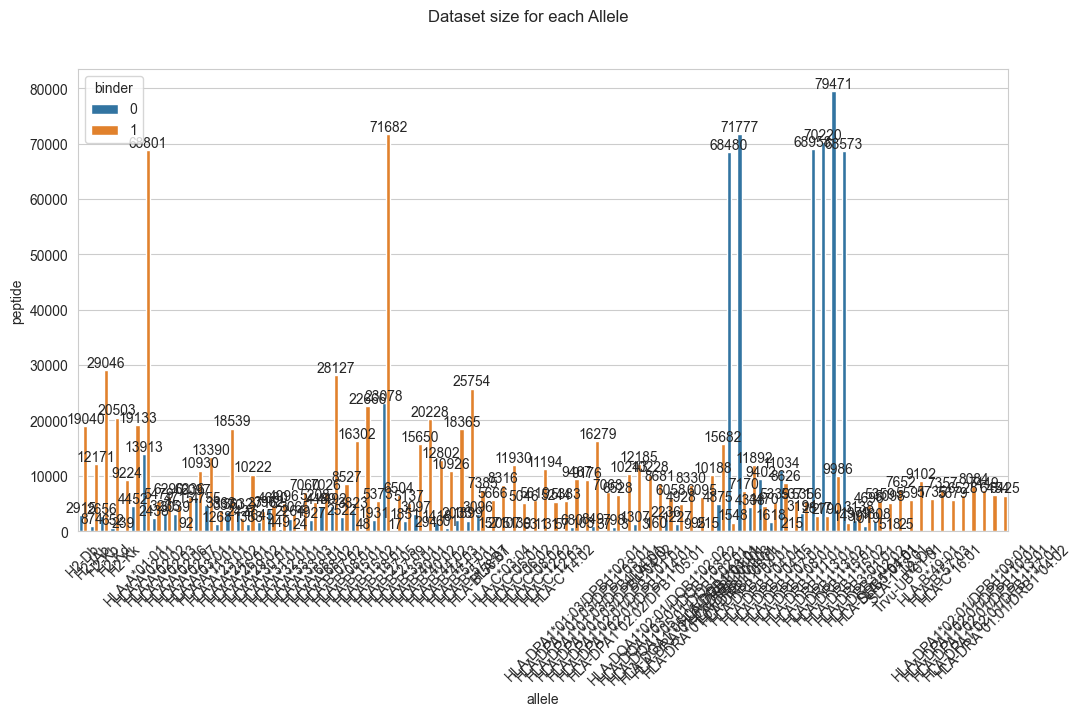

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
#target_df = df[df['binder'] == 1]
ax = sns.barplot(data=df.groupby(['binder','allele'], as_index=False)['peptide'].count(), x='allele', y='peptide', hue='binder', orient='vertical')
for container in ax.containers:
    ax.bar_label(container)
#sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for item in ax.get_xticklabels():
    item.set_rotation(45)

ax.figure.suptitle('Dataset size for each Allele')

#  Save per allele DF

In [24]:
allele_name = "HLA-DRB1*0101"

In [47]:
import mhcnames
import mhcgnomes



TARGET_PATH_TO_FILES = DATA_PATH + EXPERIMENT_NAME + '/' 

import mhcnames
import os
if not os.path.exists(TARGET_PATH_TO_FILES ):
    os.makedirs(TARGET_PATH_TO_FILES )


for allele_name in ALLELES:
    total_df = per_allele_df[allele_name]
    compact_name = mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "_")
    print(compact_name)
    
    #mhcnames.compact_allele_name(allele_name,)
    # allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    total_df.to_csv("{}data#{}.csv".format(TARGET_PATH_TO_FILES,compact_name),sep=";", index=False)

HLA-B2705
HLA-DRB1_1501
HLA-A0201
HLA-DRB1_0301
HLA-DRB1_1302
HLA-DRB1_1301
HLA-DRB1_0103
HLA-DRB1_1502
HLA-B0702
H2-Kb
HLA-B5701
HLA-A0101
HLA-B1502
H2-Db
HLA-A2402
H2-Kd
HLA-DRB1_0101
HLA-B4002
HLA-B5101
HLA-B1501
HLA-DRB1_0701
HLA-B4001
HLA-A1101
HLA-DPA1_0103-DPB1_0401
HLA-A0301
HLA-DRB1_0401
HLA-B4402
HLA-DRB1_0404
HLA-DPA1_0202-DPB1_0501
H2-AAb-ABb
HLA-C0501
HLA-A2902
HLA-B4403
HLA-A6802
HLA-C1202
HLA-B0801
HLA-B5801
HLA-DRA0101-DRB1_0401
HLA-DPA1_0201-DPB1_1401
HLA-DQ
HLA-DPA1_0103-DPB1_0201
HLA-A0203
H2-Kk
HLA-DPA1_0103-DPB1_0301
H2-Dq
HLA-DQA1_0201-DQB1_0202
HLA-A3101
HLA-DRB1_1101
HLA-C0304
HLA-DQA1_0505-DQB1_0301
HLA-DQA1_0301-DQB1_0302
HLA-DPA1_0201-DPB1_1001
HLA-A0202
HLA-A0206
SLA-1_1301
HLA-DPA1_0201-DPB1_1301
HLA-B5703
HLA-DPA1_0201-DPB1_0101
HLA-B1801
HLA-DRB5_0101
HLA-A6801
HLA-DPA1_0103-DPB1_0402
HLA-A3303
HLA-B3501
HLA-DRB1_0405
HLA-DPA1_0201-DPB1_0901
HLA-B2709
HLA-DPA1_0201-DPB1_1701
HLA-DRA0101-DRB1_0402
HLA-A0207
HLA-DRA0101-DRB1_0101
HLA-DQA1_0501-DQB1_0201
HLA

In [48]:
total_df['binder'].value_counts()

1    3138
0    1979
Name: binder, dtype: int64

In [49]:
total_df

,peptide,Epitope_Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC Restriction_Class,Assay_Response measured,Assay_Method,protein_id,peptide_start,peptide_end,measurement_type,binder,length
124,ESRLVVDFSQFSRGN,Hepatitis B virus,Positive-Low,2525.0,=,HLA-DRB3*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,385.0,399.0,quantitative,0,15
136,LQSLTNLLSSNLSWL,Hepatitis B virus,Positive-Low,1837.0,=,HLA-DRB3*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,412.0,426.0,quantitative,0,15
150,SSNLSWLSLDVSAAF,Hepatitis B virus,Positive-High,5.0,=,HLA-DRB3*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,420.0,434.0,quantitative,1,15
182,KQAFTFSPTYKAFLC,Hepatitis B virus,Positive-Low,4848.0,=,HLA-DRB3*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,NaN,664.0,678.0,quantitative,0,15
191,LCQVFADATPTGWGL,Hepatitis B virus,Positive-Low,1808.0,=,HLA-DRB3*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,694.0,708.0,quantitative,0,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2716955,VNVDFTVDTNGVY,Dependoparvovirus primate1,Positive,500.0,<,HLA-DRB3*01:01,II,ligand presentation,cellular MHC/mass spectrometry,NaN,708.0,720.0,qualitative,1,13
2716956,VNVDFTVDTNGVYS,Dependoparvovirus primate1,Positive,500.0,<,HLA-DRB3*01:01,II,ligand presentation,cellular MHC/mass spectrometry,NaN,708.0,721.0,qualitative,1,14
2716957,VNVDFTVDTNGVYSEPR,Dependoparvovirus primate1,Positive,500.0,<,HLA-DRB3*01:01,II,ligand presentation,cellular MHC/mass spectrometry,NaN,708.0,724.0,qualitative,1,17
2716958,VNVDFTVDTNGVYSEPRP,Dependoparvovirus primate1,Positive,500.0,<,HLA-DRB3*01:01,II,ligand presentation,cellular MHC/mass spectrometry,NaN,708.0,725.0,qualitative,1,18
